# Park Load Ratio — people served per 1,000 sq ft of park

**Question:** Is a park serving too many people for its size? A walkshed analysis treats every park as equal; this asks whether the population a park serves is evenly matched to its area.

**Method:** a two-step floating catchment area (2SFCA) variant with an equal-split correction, so no resident is counted more than once.

| Symbol | Meaning |
|---|---|
| $i$ | tax lot, with population $P_i$ |
| $j$ | park, with total area $A_j$ (sq ft) |
| $W_j$ | park $j$'s **5-minute** walkshed |
| $N_i$ | number of parks whose walkshed contains lot $i$'s centroid |

$$L_j = \sum_{i \in W_j} \frac{P_i}{N_i} \qquad\qquad R_j = \frac{1000\,L_j}{A_j}\ \text{(people served per 1,000 sq ft)}$$

**Check:** $\sum_j L_j$ = total population with $N_i \ge 1$ — people are split, never duplicated.

**This run (test):** every Brooklyn resident counts toward load, but results are reported for the parks serving Clinton Hill, Prospect Heights and Crown Heights (North and South). Parks are grouped by natural breaks, with no judgement yet of what counts as overloaded.

**Deferred for later versions:** park-category weighting (flagships), 2- and 10-minute walksheds, usable-area correction, lot-level access view.

## 0. Setup

In [231]:
import warnings
from pathlib import Path

import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap, to_hex, to_rgb
import pandas as pd
import requests
from shapely.geometry import box

warnings.filterwarnings(
    "ignore", message="Numba not installed"
)  # mapclassify falls back to pure Python
warnings.filterwarnings(
    "ignore", message="The GeoDataFrame you are attempting to plot is empty"
)  # empty layers in the toy run

CRS = "EPSG:2263"  # NY State Plane Long Island, US feet -> areas come out in sq ft

# Set True to run the worked example from the spec (no data needed).
# Set False to run on your own files.
USE_TOY_DATA = False

## 1. Configuration — map your columns here

Paths point at the outputs of the two earlier notebooks:
- **Parks + per-park walksheds:** `Park_Walksheds_Bklyn.ipynb`, section 11
- **Population per tax lot:** `Population_Distribution_Test.ipynb`, Part 2 (one GeoParquet per Brooklyn NTA)

**Test area.** All Brooklyn lots are loaded, so every park's load and every lot's $N_i$ are complete. Results are then reported only for parks that serve the `STUDY_NTAS`. Otherwise edge parks such as Prospect Park would miss the residents on their far side and look emptier than they are.

In [ ]:
ROOT = Path("/Users/temp/Documents/GitHub/MappingAffordances")

# --- File paths ---
PARKS_PATH = (
    ROOT / "Data_Output/Walksheds/bklyn_parks.parquet"
)  # Park_Walksheds_Bklyn.ipynb §11
WALKSHEDS_PATH = (
    ROOT / "Data_Output/Walksheds/bklyn_walksheds_per_park.parquet"
)  # Park_Walksheds_Bklyn.ipynb §11
LOTS_DIR = ROOT / "Data_Output/Population/Brooklyn"  # one parquet per NTA
OUT_DIR = ROOT / "Data_Output/ParkLoad"
EXPORT_NAME_TEST = "ParkLoad5_Bkyln_SampleNeighborhood_Test"  # test-area exports (csv, html, png)
EXPORT_NAME_BK = "ParkLoad5_Bkyln"  # Brooklyn-wide exports

# --- Column names ---
PARK_ID = "park_id"  # unique id in parks layer
PARK_NAME = "park_name"
WALK_PARK_ID = "park_id"  # field in walksheds linking back to the park
WALK_MINUTES = (
    "minutes"  # field holding 2 / 5 / 10 (set to None if the layer is 5-min only)
)
LOT_ID = "BBL"  # unique id per tax lot
LOT_POP = "est_pop_per_lot"  # estimated residents per lot
LOT_NTA = "nta2020"  # neighborhood code on each lot

MINUTES = 5  # walkshed band used in this run

# --- Test area: same NTAs as Population_Distribution_Test.ipynb Part 1 ---
STUDY_NTAS = ["BK0204", "BK0801", "BK0802", "BK0901"]
STUDY_NAME = "Clinton Hill, Prospect Heights & Crown Heights"

# --- Classification ---
N_CLASSES = 4  # natural-breaks classes
CLASSIFY_LOG = (
    True  # classify on log10(people per 1,000 sq ft); the ratio is heavily right-skewed
)

# --- Colours: class 1 (most people per 1,000 sq ft) -> class k (fewest) ---
CMAP = "magma"
CMAP_RANGE = (
    0.2,
    0.7,
)  # dark purple -> pink: skips magma's near-black start and its yellow end
# Vibrancy per class, 1 = full colour, 0 = white (stretched to fit if N_CLASSES changes).
# Classes 1-2 stay full strength; 3-4 fade toward white.
CMAP_VIBRANCY = (1.0, 1.0, 0.55, 0.25)

# Comparison colormap, drawn next to CMAP in the static maps
CMAP_ALT = "spring"
CMAP_ALT_RANGE = (0.0, 1.0)  # class 1 = magenta ... class k = yellow
# Vibrancy per class, 1 = full colour, 0 = white (stretched to fit if N_CLASSES changes).
# Classes 1-2 stay full strength; 3-4 fade toward white.
CMAP_ALT_VIBRANCY = (1.0, 1.0, 0.55, 0.25)

# (colormap, range, vibrancy) for each panel of the static maps
COLORMAPS = [
    (CMAP, CMAP_RANGE, CMAP_VIBRANCY),
    (CMAP_ALT, CMAP_ALT_RANGE, CMAP_ALT_VIBRANCY),
]

# --- Walkshed pull-back (sections 18-21) ---
TARGET_MAX = 81  # people per 1,000 sq ft, upper bound of class 3
BASE_MINUTES = 5

# --- Walkshed display (section 20 figure only; calculations use the street-based walksheds) ---
SHED_STYLE = "solid"  # "solid" = one continuous area per walkshed; "streets" = buffered streets as computed
SOLID_CLOSE_FT = 250  # gaps between reachable streets narrower than ~2x this are filled

## 2. Load data

The toy branch rebuilds the worked example: Lot A reaches Park 1 only, Lot B reaches both, Lot C reaches Park 2 only. Park 1 is 30,000 sq ft and Park 2 is 6,000 sq ft. Toy park 3 (1,000 sq ft) has its own lots D, E and F, far from A–C, so it doesn't change parks 1 and 2. It is overloaded and tests the pull-back in sections 18–19. Expected result for parks 1 and 2: $R_1 = 1000 \times 200 / 30{,}000 = 6.67$ and $R_2 = 1000 \times 160 / 6{,}000 = 26.67$ people per 1,000 sq ft.

In [233]:
if USE_TOY_DATA:
    parks = gpd.GeoDataFrame(
        {PARK_ID: [1, 2, 3], PARK_NAME: ["Park 1", "Park 2", "Park 3"]},
        geometry=[
            box(0, 0, 150, 200),  # 30,000 sq ft
            box(1000, 0, 1060, 100),  #  6,000 sq ft
            box(3000, 0, 3020, 50),  #  1,000 sq ft
        ],
        crs=CRS,
    )
    walksheds = gpd.GeoDataFrame(
        {WALK_PARK_ID: [1, 2, 3], WALK_MINUTES: [5, 5, 5]},
        geometry=[
            box(-400, -400, 700, 600),  # covers lots A and B
            box(500, -400, 1500, 600),  # covers lots B and C
            box(2700, -300, 3400, 400),  # covers lots D, E and F
        ],
        crs=CRS,
    )
    lots = gpd.GeoDataFrame(
        {
            LOT_ID: ["A", "B", "C", "D", "E", "F"],
            LOT_POP: [100, 200, 60, 40, 30, 50],
            LOT_NTA: STUDY_NTAS[0],
        },
        geometry=[
            box(200, 300, 250, 350),  # centroid x=225  -> W1 only
            box(575, 300, 625, 350),  # centroid x=600  -> W1 and W2
            box(1100, 300, 1150, 350),  # centroid x=1125 -> W2 only
            box(3045, 20, 3055, 30),  # D: centroid 30 ft from park 3 -> W3 only
            box(3095, 20, 3105, 30),  # E: centroid 80 ft from park 3 -> W3 only
            box(3195, 20, 3205, 30),  # F: centroid 180 ft from park 3 -> W3 only
        ],
        crs=CRS,
    )
    study_area = gpd.GeoDataFrame(geometry=[box(*lots.total_bounds)], crs=CRS)
else:
    parks = gpd.read_parquet(PARKS_PATH)
    walksheds = gpd.read_parquet(WALKSHEDS_PATH)

    lot_files = sorted(LOTS_DIR.glob("BK*.parquet"))
    lot_parts = [
        gdf for gdf in (gpd.read_parquet(f) for f in lot_files) if len(gdf) > 0
    ]
    lots = gpd.GeoDataFrame(
        pd.concat(lot_parts, ignore_index=True), crs=lot_parts[0].crs
    )

    # Study-area outline (for maps and for spotting parks with no walkshed)
    r = requests.get(
        "https://data.cityofnewyork.us/resource/9nt8-h7nd.geojson",
        params={"$where": "nta2020 in(" + ",".join(f"'{c}'" for c in STUDY_NTAS) + ")"},
    )
    r.raise_for_status()
    study_area = gpd.GeoDataFrame.from_features(r.json(), crs=4326)[
        ["nta2020", "ntaname", "geometry"]
    ]
    print(f"Lot files: {len(lot_files)} NTAs ({len(lot_parts)} with lots)")

print(f"parks: {len(parks):,}   walksheds: {len(walksheds):,}   lots: {len(lots):,}")

Lot files: 69 NTAs (68 with lots)
parks: 472   walksheds: 1,395   lots: 275,618


## 3. Prepare — project to feet, filter to 5-minute walksheds

All three layers must share a projected CRS in feet, or areas and point-in-polygon tests will be wrong.

In [234]:
parks = parks.to_crs(CRS)
walksheds = walksheds.to_crs(CRS)
lots = lots.to_crs(CRS)
study_area = study_area.to_crs(CRS)

if WALK_MINUTES is not None:
    walksheds = walksheds[walksheds[WALK_MINUTES] == MINUTES].copy()

assert lots[LOT_ID].is_unique, "A tax lot appears in more than one NTA file"

# Lots with no residents can't add load; drop them and any missing values
lots = lots[lots[LOT_POP].fillna(0) > 0].copy()

# Every walkshed should point to a real park
missing = set(walksheds[WALK_PARK_ID]) - set(parks[PARK_ID])
assert (
    not missing
), f"Walksheds reference parks not in parks layer: {list(missing)[:10]}"

# Parks with no street access node have no walkshed, so they can't be rated
parks["has_walkshed"] = parks[PARK_ID].isin(walksheds[WALK_PARK_ID])

print(
    f"{MINUTES}-min walksheds: {len(walksheds):,}   populated lots: {len(lots):,}   "
    f"population: {lots[LOT_POP].sum():,.0f}"
)
print(f"Parks without a walkshed: {(~parks['has_walkshed']).sum():,} of {len(parks):,}")

5-min walksheds: 465   populated lots: 249,298   population: 2,731,902
Parks without a walkshed: 7 of 472


## 4. Park area $A_j$

Total polygon area in sq ft. (Usable-area correction comes later.)

In [235]:
parks["area_sqft"] = parks.geometry.area
parks[[PARK_ID, "area_sqft"]].head()

,park_id,area_sqft
0,0,6.665350e+06
1,1,6.610112e+06
2,2,4.384583e+06
3,3,6.810924e+05
4,4,2.193939e+06


## 5. Lot centroids

Each lot becomes one point. A lot is counted entirely in or entirely out of a walkshed, based on where its centroid lands.

In [236]:
lot_pts = lots[[LOT_ID, LOT_POP]].copy()
lot_pts = gpd.GeoDataFrame(lot_pts, geometry=lots.geometry.centroid, crs=CRS)

## 6. Membership — which lots fall in which walksheds

A spatial join gives one row per (lot, park) pair where the lot's centroid is inside that park's walkshed. Duplicates are dropped in case a park's walkshed is stored as several polygons.

In [237]:
membership = gpd.sjoin(
    lot_pts,
    walksheds[[WALK_PARK_ID, "geometry"]],
    how="inner",
    predicate="within",
)[[LOT_ID, LOT_POP, WALK_PARK_ID]].drop_duplicates(subset=[LOT_ID, WALK_PARK_ID])

membership = membership.rename(columns={WALK_PARK_ID: PARK_ID})
print(f"{len(membership):,} lot–park pairs")
membership.head()

396,279 lot–park pairs


,BBL,est_pop_per_lot,park_id
2,3024770001,18.509804,18
2,3024770001,18.509804,70
2,3024770001,18.509804,72
2,3024770001,18.509804,437
4,3024790001,12.956863,18


## 7. $N_i$ — number of parks each lot can reach

Lots that never appear in `membership` have $N_i = 0$. They're set aside as the **no-access** population.

In [238]:
n_parks = membership.groupby(LOT_ID).size().rename("n_parks")
membership = membership.join(n_parks, on=LOT_ID)

no_access = lots[~lots[LOT_ID].isin(n_parks.index)]
print(f"Lots with access:    {n_parks.size:,}")
print(
    f"Lots with no access: {len(no_access):,}  ({no_access[LOT_POP].sum():,.0f} people)"
)
n_parks.value_counts().sort_index().rename("lots").to_frame()

Lots with access:    191,741
Lots with no access: 57,557  (706,349 people)


,lots
n_parks,
1,86986
2,55126
3,27227
4,11737
5,5180
6,1903
7,963
8,687
9,609


## 8. Equal split — $P_i / N_i$

Each park reachable from a lot receives an equal share of that lot's population.

In [239]:
membership["pop_share"] = membership[LOT_POP] / membership["n_parks"]
membership.head()

,BBL,est_pop_per_lot,park_id,n_parks,pop_share
2,3024770001,18.509804,18,4,4.627451
2,3024770001,18.509804,70,4,4.627451
2,3024770001,18.509804,72,4,4.627451
2,3024770001,18.509804,437,4,4.627451
4,3024790001,12.956863,18,4,3.239216


## 9. Park load $L_j$

In [240]:
load = membership.groupby(PARK_ID)["pop_share"].sum().rename("load")
parks = parks.merge(load, on=PARK_ID, how="left")
parks["load"] = parks["load"].fillna(0)

## 10. Ratio $R_j = 1000\,L_j / A_j$ — people per 1,000 sq ft

Higher means more people sharing each 1,000 sq ft of park. Parks with zero load (no populated lots in their walkshed) get 0 and are flagged as `no_residents`; they aren't rated.

`sqft_per_person` (the inverse, $A_j / L_j$) is kept as a secondary column.

In [241]:
parks["people_per_1000sqft"] = 1000 * parks["load"] / parks["area_sqft"]
parks["sqft_per_person"] = np.where(
    parks["load"] > 0, parks["area_sqft"] / parks["load"], np.nan
)
parks["no_residents"] = parks["load"] == 0

parks[[PARK_ID, "area_sqft", "load", "people_per_1000sqft"]].sort_values(
    "people_per_1000sqft", ascending=False
)

,park_id,area_sqft,load,people_per_1000sqft
326,326,521.643448,8838.170229,16942.933475
315,315,788.385469,10119.527294,12835.760794
313,313,501.828754,6247.834205,12450.131958
280,280,1383.726669,13084.033006,9455.648500
417,417,137.982080,1135.430363,8228.824799
...,...,...,...,...
136,136,30930.024268,0.000000,0.000000
237,237,1721.807225,0.000000,0.000000
168,168,22509.093656,0.000000,0.000000
43,43,296869.333097,0.000000,0.000000


## 11. Checks

In [242]:
pop_with_access = lots.loc[lots[LOT_ID].isin(n_parks.index), LOT_POP].sum()
total_load = parks["load"].sum()
print(f"Σ L_j = {total_load:,.2f}   population with access = {pop_with_access:,.2f}")
assert np.isclose(
    total_load, pop_with_access
), "Conservation check failed: people were lost or duplicated"

print(f"Parks with no residents in walkshed: {parks['no_residents'].sum():,}")

if USE_TOY_DATA:
    got = parks.set_index(PARK_ID).loc[[1, 2], "people_per_1000sqft"].round(2).to_dict()
    assert got == {1: 6.67, 2: 26.67}, got
    print(
        "Toy example matches hand calculation: R1 = 6.67, R2 = 26.67 people per 1,000 sq ft ✓"
    )

Σ L_j = 2,025,552.88   population with access = 2,025,552.88
Parks with no residents in walkshed: 11


## 12. Restrict to the test area

The **test parks** are the parks whose 5-minute walkshed reaches at least one populated lot in `STUDY_NTAS`. Their load $L_j$ still counts everyone they serve, inside the study area and out.

`pct_load_from_study` shows how much of each park's load comes from inside the study area. A low share marks an edge park, one that mostly serves a neighbouring area.

In [243]:
study_lot_ids = set(lots.loc[lots[LOT_NTA].isin(STUDY_NTAS), LOT_ID])
membership["in_study"] = membership[LOT_ID].isin(study_lot_ids)

load_from_study = membership[membership["in_study"]].groupby(PARK_ID)["pop_share"].sum()

test_parks = parks[parks[PARK_ID].isin(load_from_study.index)].copy()
test_parks["acres"] = test_parks["area_sqft"] / 43_560
test_parks["load_from_study"] = test_parks[PARK_ID].map(load_from_study)
test_parks["pct_load_from_study"] = test_parks["load_from_study"] / test_parks["load"]

study_pop = lots.loc[lots[LOT_ID].isin(study_lot_ids), LOT_POP].sum()
print(
    f"Study area population: {study_pop:,.0f} on {len(study_lot_ids):,} populated lots"
)
print(f"Test parks (5-min walkshed reaches the study area): {len(test_parks)}")

# Parks inside the study area that couldn't be rated (no street access node -> no walkshed)
unrated = parks[~parks["has_walkshed"] & parks.intersects(study_area.union_all())]
print(f"Parks in the study area with no walkshed (not rated): {len(unrated)}")
if len(unrated):
    print(
        unrated.assign(acres=unrated["area_sqft"] / 43_560)[
            [PARK_ID, PARK_NAME, "acres"]
        ]
        .round(2)
        .to_string(index=False)
    )

# Edge parks: most of their load comes from outside the study area
test_parks.sort_values("pct_load_from_study")[
    [PARK_ID, PARK_NAME, "acres", "load", "load_from_study", "pct_load_from_study"]
].head(15).round(2)

Study area population: 188,027 on 12,056 populated lots
Test parks (5-min walkshed reaches the study area): 49
Parks in the study area with no walkshed (not rated): 0


,park_id,park_name,acres,load,load_from_study,pct_load_from_study
79,79,Green Space @ President Street,0.05,6129.14,3.47,0.00
353,353,Brevoort Playground,1.51,3677.96,25.07,0.01
221,221,John Hancock Playground,1.31,9470.99,107.82,0.01
76,76,Classon Triangle,0.11,2478.43,59.88,0.02
35,35,Fort Greene Park,28.95,6832.80,175.35,0.03
214,214,Classon Playground,0.42,2461.55,75.64,0.03
11,11,Prospect Park,464.25,31933.65,1312.07,0.04
175,175,Jackie Robinson Park,1.56,2712.65,120.75,0.04
143,143,Park Slope Playground,1.01,5508.13,282.04,0.05
216,216,Star Spangled Banner Playground,0.59,4214.03,229.19,0.05


## 13. Overlapping parks (diagnostic)

The parks layer comes from OpenStreetMap, which often maps playgrounds and gardens as their own polygons *inside* a larger park. That causes two distortions:
- the overlapping area is counted twice, once in each park's $A_j$;
- lots nearby reach more "parks", so $N_i$ goes up and the larger park's share of their population goes down.

The table lists test parks with at least 90% of their area inside another park. **Nothing is changed here.** It is for reviewing whether to merge or drop these parks in a later version.

In [244]:
others = parks[[PARK_ID, PARK_NAME, "geometry"]].rename(
    columns={PARK_ID: "container_id", PARK_NAME: "container_name"}
)
pairs = gpd.sjoin(
    test_parks[[PARK_ID, PARK_NAME, "area_sqft", "geometry"]],
    others,
    predicate="intersects",
)
pairs = pairs[pairs[PARK_ID] != pairs["container_id"]]

container_geom = others.set_index("container_id").geometry
pairs["pct_inside"] = [
    geom.intersection(container_geom[cid]).area
    for geom, cid in zip(pairs.geometry, pairs["container_id"])
] / pairs["area_sqft"]

nested = pairs[pairs["pct_inside"] >= 0.9].sort_values("pct_inside", ascending=False)
print(
    f"Test parks mostly inside another park: {nested[PARK_ID].nunique()} of {len(test_parks)}"
)
nested[[PARK_ID, PARK_NAME, "container_id", "container_name", "pct_inside"]].round(2)

Test parks mostly inside another park: 0 of 49


,park_id,park_name,container_id,container_name,pct_inside


## 14. Classification — natural breaks

Test parks are grouped by **Fisher-Jenks natural breaks**, which place class boundaries at the biggest gaps in the data so that each class is as internally similar as possible. Classes are numbered from **1 (most people per 1,000 sq ft)** to **k (fewest)**. For now these are statistical groupings only, not judgements of whether a park is overloaded. Colours come from the magma colormap: dark purple is class 1, pale pink is class k.

`add_classes()` is reused in section 16 for all of Brooklyn.

With `CLASSIFY_LOG = True` the breaks are found on $\log_{10}(R_j)$. The ratio spans several orders of magnitude, so on the raw scale one or two large parks would take a class each and almost every other park would land in class 1. Breaks are reported back in people per 1,000 sq ft.

**Goodness of variance fit (GVF)** measures how much of the total variance the classes explain (1 = perfect). The table below shows it for several values of k: pick the point where adding a class stops improving GVF much.

In [245]:
def gvf(x, yb):
    """Goodness of variance fit: 1 - (within-class squared deviations / total squared deviations)."""
    sdam = ((x - x.mean()) ** 2).sum()
    sdcm = sum(((x[yb == c] - x[yb == c].mean()) ** 2).sum() for c in np.unique(yb))
    return 1 - sdcm / sdam


def vibrancy_levels(k, vibrancy):
    """Share of full colour for each of k classes (1 = full, 0 = white)."""
    if vibrancy is None:
        return np.ones(k)
    return np.interp(np.linspace(0, 1, k), np.linspace(0, 1, len(vibrancy)), vibrancy)


def class_colors(k, cmap=CMAP, cmap_range=CMAP_RANGE, vibrancy=CMAP_VIBRANCY):
    """k colours sampled from cmap over cmap_range: class 1 (most people per 1,000 sq ft) first ... class k last."""
    ramp = plt.get_cmap(cmap)
    colors = np.array([ramp(v)[:3] for v in np.linspace(*cmap_range, k)])
    levels = vibrancy_levels(k, vibrancy)[:, None]
    colors = colors * levels + (1 - levels)  # blend toward white
    return [to_hex(col) for col in colors]


def fmt(v):
    return f"{v:,.1f}" if v < 10 else f"{v:,.0f}"


def add_classes(df, n_classes=N_CLASSES, log=CLASSIFY_LOG):
    """Natural-breaks classes on people per 1,000 sq ft, class 1 = most crowded.
    Adds load_class, class_range, class_label, class_color.
    Returns k and a GVF-by-k table (None if too few parks)."""
    ratio = df["people_per_1000sqft"].to_numpy()
    x = np.log10(ratio) if log else ratio
    n_distinct = len(np.unique(x))

    gvf_table = None
    if n_distinct >= 3:
        gvf_table = (
            pd.Series(
                {
                    k: gvf(x, mapclassify.FisherJenks(x, k=k).yb)
                    for k in range(2, min(7, n_distinct - 1) + 1)
                },
                name="GVF",
            )
            .rename_axis("k")
            .round(3)
        )

    k = min(n_classes, n_distinct)
    fj = mapclassify.FisherJenks(x, k=k)

    # Bin upper bounds (lowest bin first), converted back to people per 1,000 sq ft
    upper = 10**fj.bins if log else fj.bins
    lower = np.r_[ratio.min(), upper[:-1]]
    ranges = [f"{fmt(lo)}–{fmt(hi)} people/1,000 sq ft" for lo, hi in zip(lower, upper)]

    # Flip so the highest bin (most crowded) is class 1
    df["load_class"] = k - fj.yb
    df["class_range"] = [ranges[b] for b in fj.yb]
    df["class_label"] = df["load_class"].astype(str) + ": " + df["class_range"]
    df["class_color"] = df["load_class"].map(dict(enumerate(class_colors(k), start=1)))
    return k, gvf_table


k, gvf_table = add_classes(test_parks)
if gvf_table is not None:
    print(gvf_table.to_string(), "\n")
print(test_parks.groupby("class_label").size().rename("parks").to_string())

k
2    0.549
3    0.772
4    0.895
5    0.942
6    0.961
7    0.971 

class_label
1: 527–5,719 people/1,000 sq ft     5
2: 88–527 people/1,000 sq ft       21
3: 5.4–88 people/1,000 sq ft       21
4: 1.6–5.4 people/1,000 sq ft       2


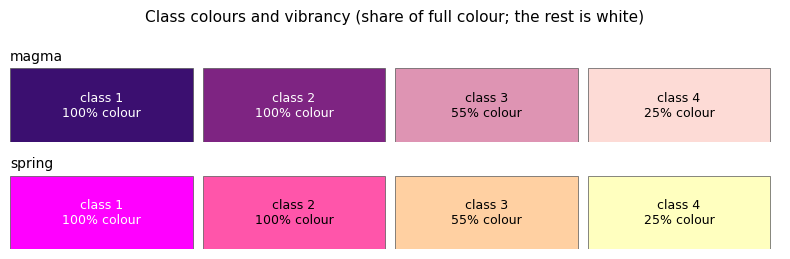

In [246]:
# Vibrancy scale: each palette's class colours and how much of the full colour each keeps
fig, axes = plt.subplots(len(COLORMAPS), 1, figsize=(8, 1.3 * len(COLORMAPS)))
for ax, (cmap, cmap_range, vibrancy) in zip(np.atleast_1d(axes), COLORMAPS):
    colors = class_colors(k, cmap, cmap_range, vibrancy)
    for i, (col, level) in enumerate(zip(colors, vibrancy_levels(k, vibrancy))):
        r, g, b = to_rgb(col)
        text_color = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black"
        ax.add_patch(plt.Rectangle((i, 0), 0.95, 1, color=col, ec="#555555", lw=0.5))
        ax.text(
            i + 0.475,
            0.5,
            f"class {i + 1}\n{level:.0%} colour",
            ha="center",
            va="center",
            fontsize=9,
            color=text_color,
        )
    ax.set_xlim(0, k)
    ax.set_ylim(0, 1)
    ax.set_axis_off()
    ax.set_title(cmap, loc="left", fontsize=10)
fig.suptitle(
    "Class colours and vibrancy (share of full colour; the rest is white)", fontsize=11
)
plt.tight_layout()
plt.show()

In [247]:
results = (
    test_parks[
        [
            PARK_ID,
            PARK_NAME,
            "acres",
            "load",
            "people_per_1000sqft",
            "load_class",
            "class_range",
            "pct_load_from_study",
        ]
    ]
    .sort_values("people_per_1000sqft", ascending=False)
    .round({"acres": 2, "load": 0, "people_per_1000sqft": 2, "pct_load_from_study": 2})
    .reset_index(drop=True)
)
results

,park_id,park_name,acres,load,people_per_1000sqft,load_class,class_range,pct_load_from_study
0,86,Gaynor Plaza,0.02,4448.0,5718.77,1,"527–5,719 people/1,000 sq ft",0.47
1,79,Green Space @ President Street,0.05,6129.0,2892.43,1,"527–5,719 people/1,000 sq ft",0.00
2,239,Grant Gore Triangle,0.14,12384.0,2083.48,1,"527–5,719 people/1,000 sq ft",0.96
3,97,Person Square,0.04,2572.0,1569.78,1,"527–5,719 people/1,000 sq ft",0.06
4,145,Pitkin Plaza,0.10,3075.0,736.09,1,"527–5,719 people/1,000 sq ft",0.10
5,76,Classon Triangle,0.11,2478.0,527.42,2,"88–527 people/1,000 sq ft",0.02
6,44,Lowry Triangle,0.26,5256.0,465.48,2,"88–527 people/1,000 sq ft",0.98
7,395,Dodger Playground,0.29,5081.0,400.57,2,"88–527 people/1,000 sq ft",0.64
8,144,Zion Triangle,0.43,4085.0,220.40,2,"88–527 people/1,000 sq ft",0.13
9,246,Lafayette Gardens Playground,0.81,7287.0,207.57,2,"88–527 people/1,000 sq ft",0.07


## 15. Map — test parks by class

Test parks are coloured by natural-breaks class. Thin grey lines are their 5-minute walksheds, the black line is the study area, and other parks are shown in light grey for context.

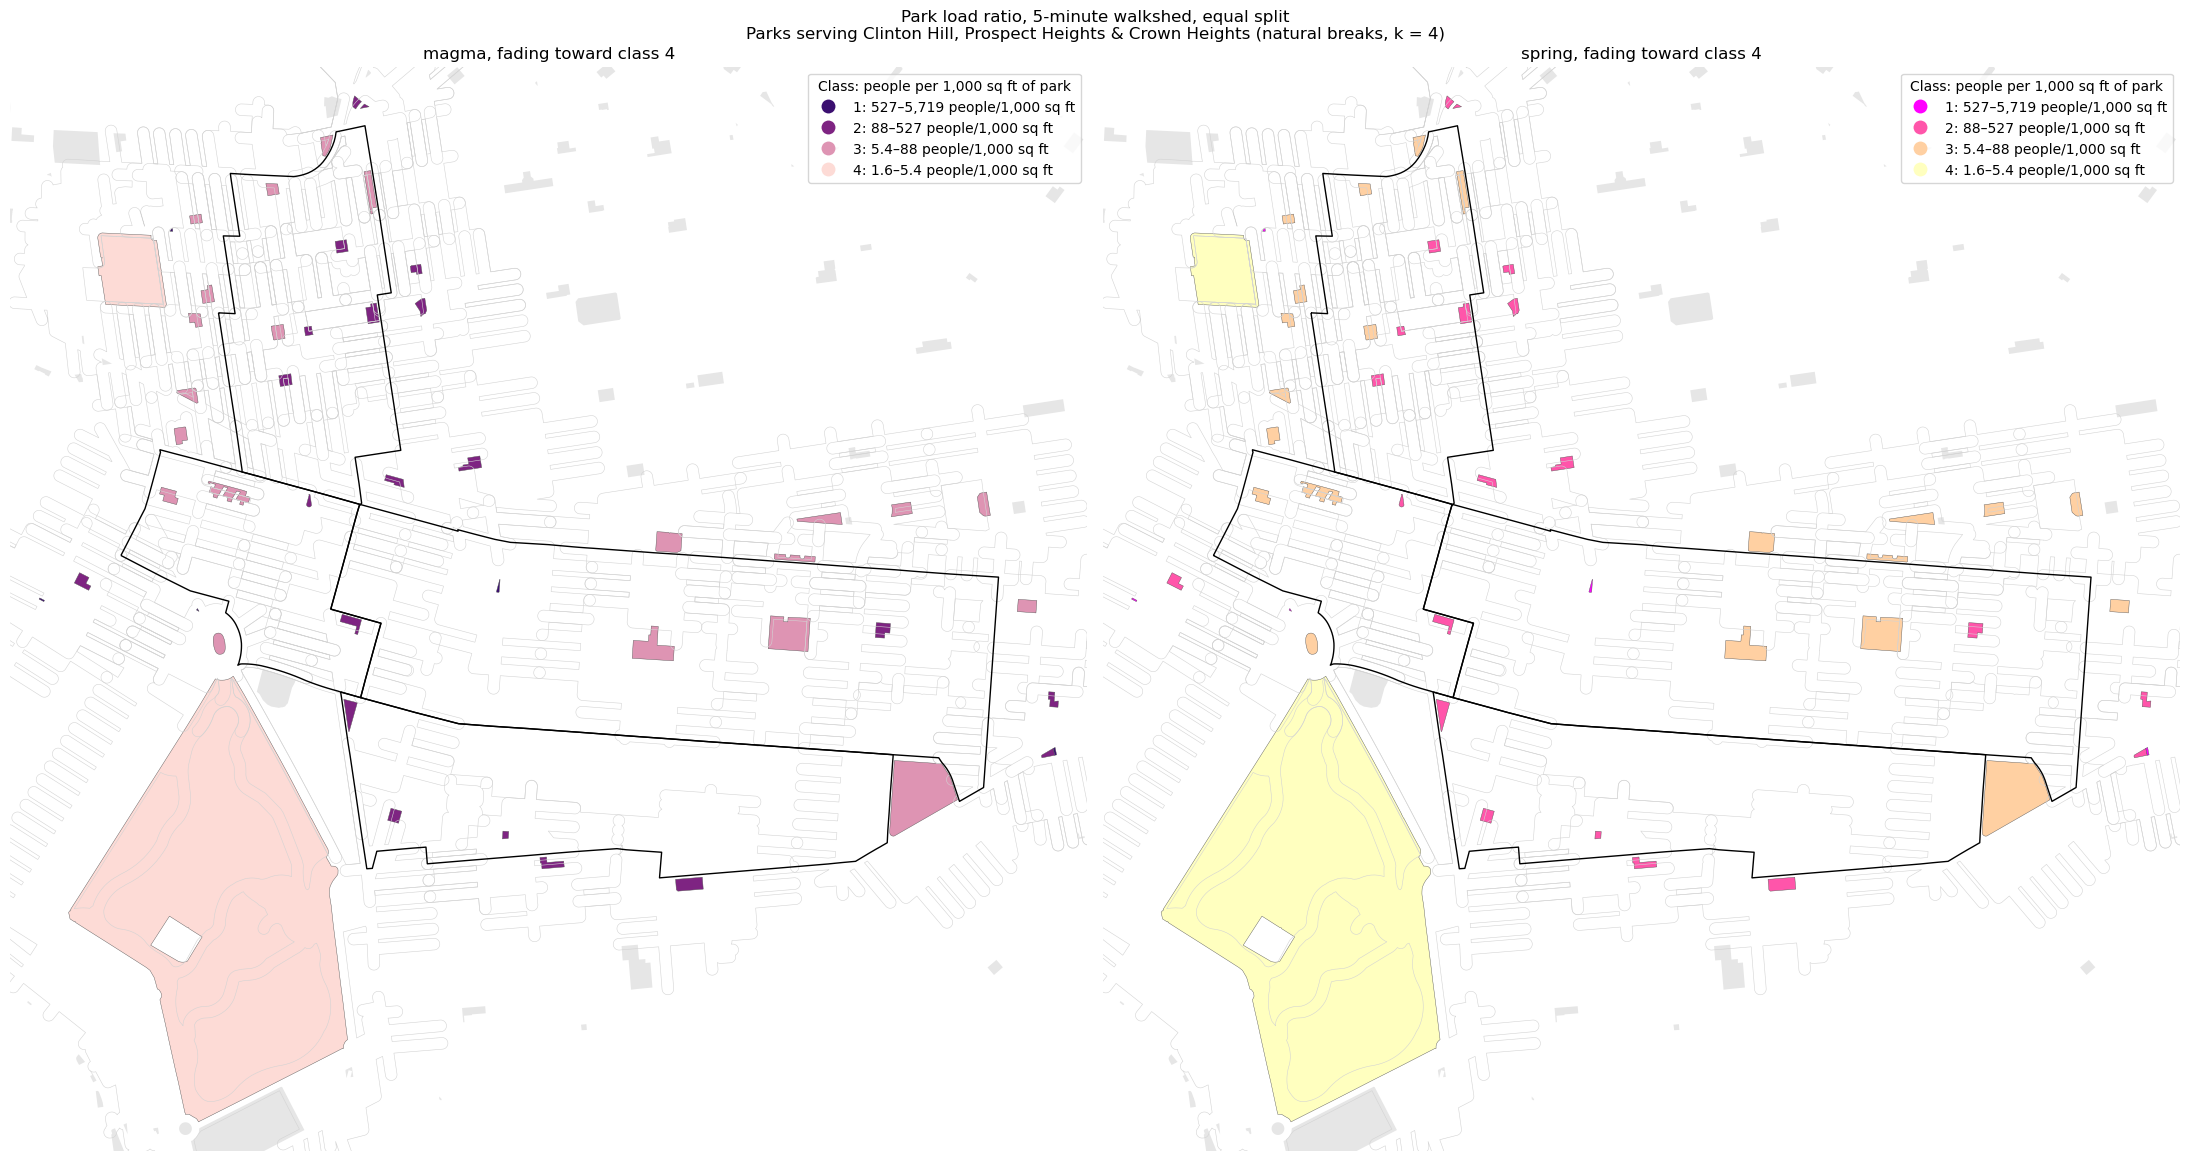

In [248]:
test_sheds = walksheds[walksheds[WALK_PARK_ID].isin(test_parks[PARK_ID])]
xmin, ymin, xmax, ymax = test_parks.total_bounds

fig, axes = plt.subplots(1, 2, figsize=(22, 12))
for ax, (cmap, cmap_range, vibrancy) in zip(axes, COLORMAPS):
    test_sheds.boundary.plot(ax=ax, color="lightgrey", linewidth=0.4)
    parks[~parks[PARK_ID].isin(test_parks[PARK_ID])].plot(
        ax=ax, color="#e6e6e6", edgecolor="none"
    )
    study_area.boundary.plot(ax=ax, color="black", linewidth=1)
    test_parks.plot(
        ax=ax,
        column="class_label",
        categorical=True,
        cmap=ListedColormap(class_colors(k, cmap, cmap_range, vibrancy)),
        edgecolor="#555555",
        linewidth=0.3,
        legend=True,
        legend_kwds={
            "title": "Class: people per 1,000 sq ft of park",
            "loc": "upper right",
        },
    )
    ax.set_xlim(xmin - 500, xmax + 500)
    ax.set_ylim(ymin - 500, ymax + 500)
    ax.set_title(cmap if vibrancy is None else f"{cmap}, fading toward class {k}")
    ax.set_axis_off()

fig.suptitle(
    f"Park load ratio, {MINUTES}-minute walkshed, equal split\n"
    f"Parks serving {STUDY_NAME} (natural breaks, k = {k})"
)
plt.tight_layout()
plt.show()

In [249]:
# Interactive version: hover a park for its numbers
m = test_sheds.explore(
    color="#999999",
    style_kwds={"fill": False, "weight": 0.5},
    tiles="Esri.WorldGrayCanvas",
    name=f"{MINUTES}-min walksheds",
)
study_area.explore(
    m=m, color="black", style_kwds={"fill": False, "weight": 2}, name="Study area"
)
test_parks.explore(
    m=m,
    column="class_label",
    categorical=True,
    cmap=class_colors(k),
    style_kwds={"fillOpacity": 0.85, "weight": 1, "color": "#555555"},
    tooltip=[
        PARK_NAME,
        "acres",
        "load",
        "people_per_1000sqft",
        "load_class",
        "pct_load_from_study",
    ],
    name="Test parks",
)
m

## 16. Brooklyn-wide classification

The same natural-breaks classification, now on **every Brooklyn park with a load**, not just the test parks. The breaks are recomputed on all of them, so a park's Brooklyn class can differ from its test-area class.

Two groups of parks are **not rated**:
- parks with no walkshed (no street access node within `ACCESS_DIST`; see `Park_Walksheds_Bklyn.ipynb`);
- parks whose 5-minute walkshed holds no residents (load = 0).

Parks near the Queens border are under-loaded: their walksheds cross into Queens, but only Brooklyn lots are counted.

The result is saved for `Park_Walksheds_Bklyn.ipynb` (section 12), which puts it on the walkshed map.

In [250]:
bk_parks = parks[parks["load"] > 0].copy()
bk_parks["acres"] = bk_parks["area_sqft"] / 43_560
bk_k, bk_gvf = add_classes(bk_parks)

if bk_gvf is not None:
    print(bk_gvf.to_string(), "\n")
print(f"Rated parks: {len(bk_parks)} of {len(parks)}")
print(f"  not rated, no walkshed:           {(~parks['has_walkshed']).sum()}")
print(
    f"  not rated, no residents in shed:  {(parks['has_walkshed'] & parks['no_residents']).sum()}\n"
)
print(bk_parks.groupby("class_label").size().rename("parks").to_string())

bk_results = (
    bk_parks[
        [
            PARK_ID,
            PARK_NAME,
            "acres",
            "load",
            "people_per_1000sqft",
            "load_class",
            "class_range",
        ]
    ]
    .sort_values("people_per_1000sqft", ascending=False)
    .round({"acres": 2, "load": 0, "people_per_1000sqft": 2})
    .reset_index(drop=True)
)
bk_results

k
2    0.565
3    0.810
4    0.881
5    0.922
6    0.947
7    0.960 

Rated parks: 461 of 472
  not rated, no walkshed:           7
  not rated, no residents in shed:  4

class_label
1: 584–16,943 people/1,000 sq ft     73
2: 84–584 people/1,000 sq ft        154
3: 11–84 people/1,000 sq ft         177
4: 0.1–11 people/1,000 sq ft         57


,park_id,park_name,acres,load,people_per_1000sqft,load_class,class_range
0,326,Ketchum Triangle,0.01,8838.0,16942.93,1,"584–16,943 people/1,000 sq ft"
1,315,Samuel Goldberg Triangle,0.02,10120.0,12835.76,1,"584–16,943 people/1,000 sq ft"
2,313,NaN,0.01,6248.0,12450.13,1,"584–16,943 people/1,000 sq ft"
3,280,Alben Square,0.03,13084.0,9455.65,1,"584–16,943 people/1,000 sq ft"
4,417,NaN,0.00,1135.0,8228.82,1,"584–16,943 people/1,000 sq ft"
...,...,...,...,...,...,...,...
456,332,Luna Playground,1.80,50.0,0.64,4,"0.1–11 people/1,000 sq ft"
457,5,McGuire Fields,83.62,2017.0,0.55,4,"0.1–11 people/1,000 sq ft"
458,14,Under The K Bridge Park,5.64,91.0,0.37,4,"0.1–11 people/1,000 sq ft"
459,257,Plumb Beach,68.81,631.0,0.21,4,"0.1–11 people/1,000 sq ft"


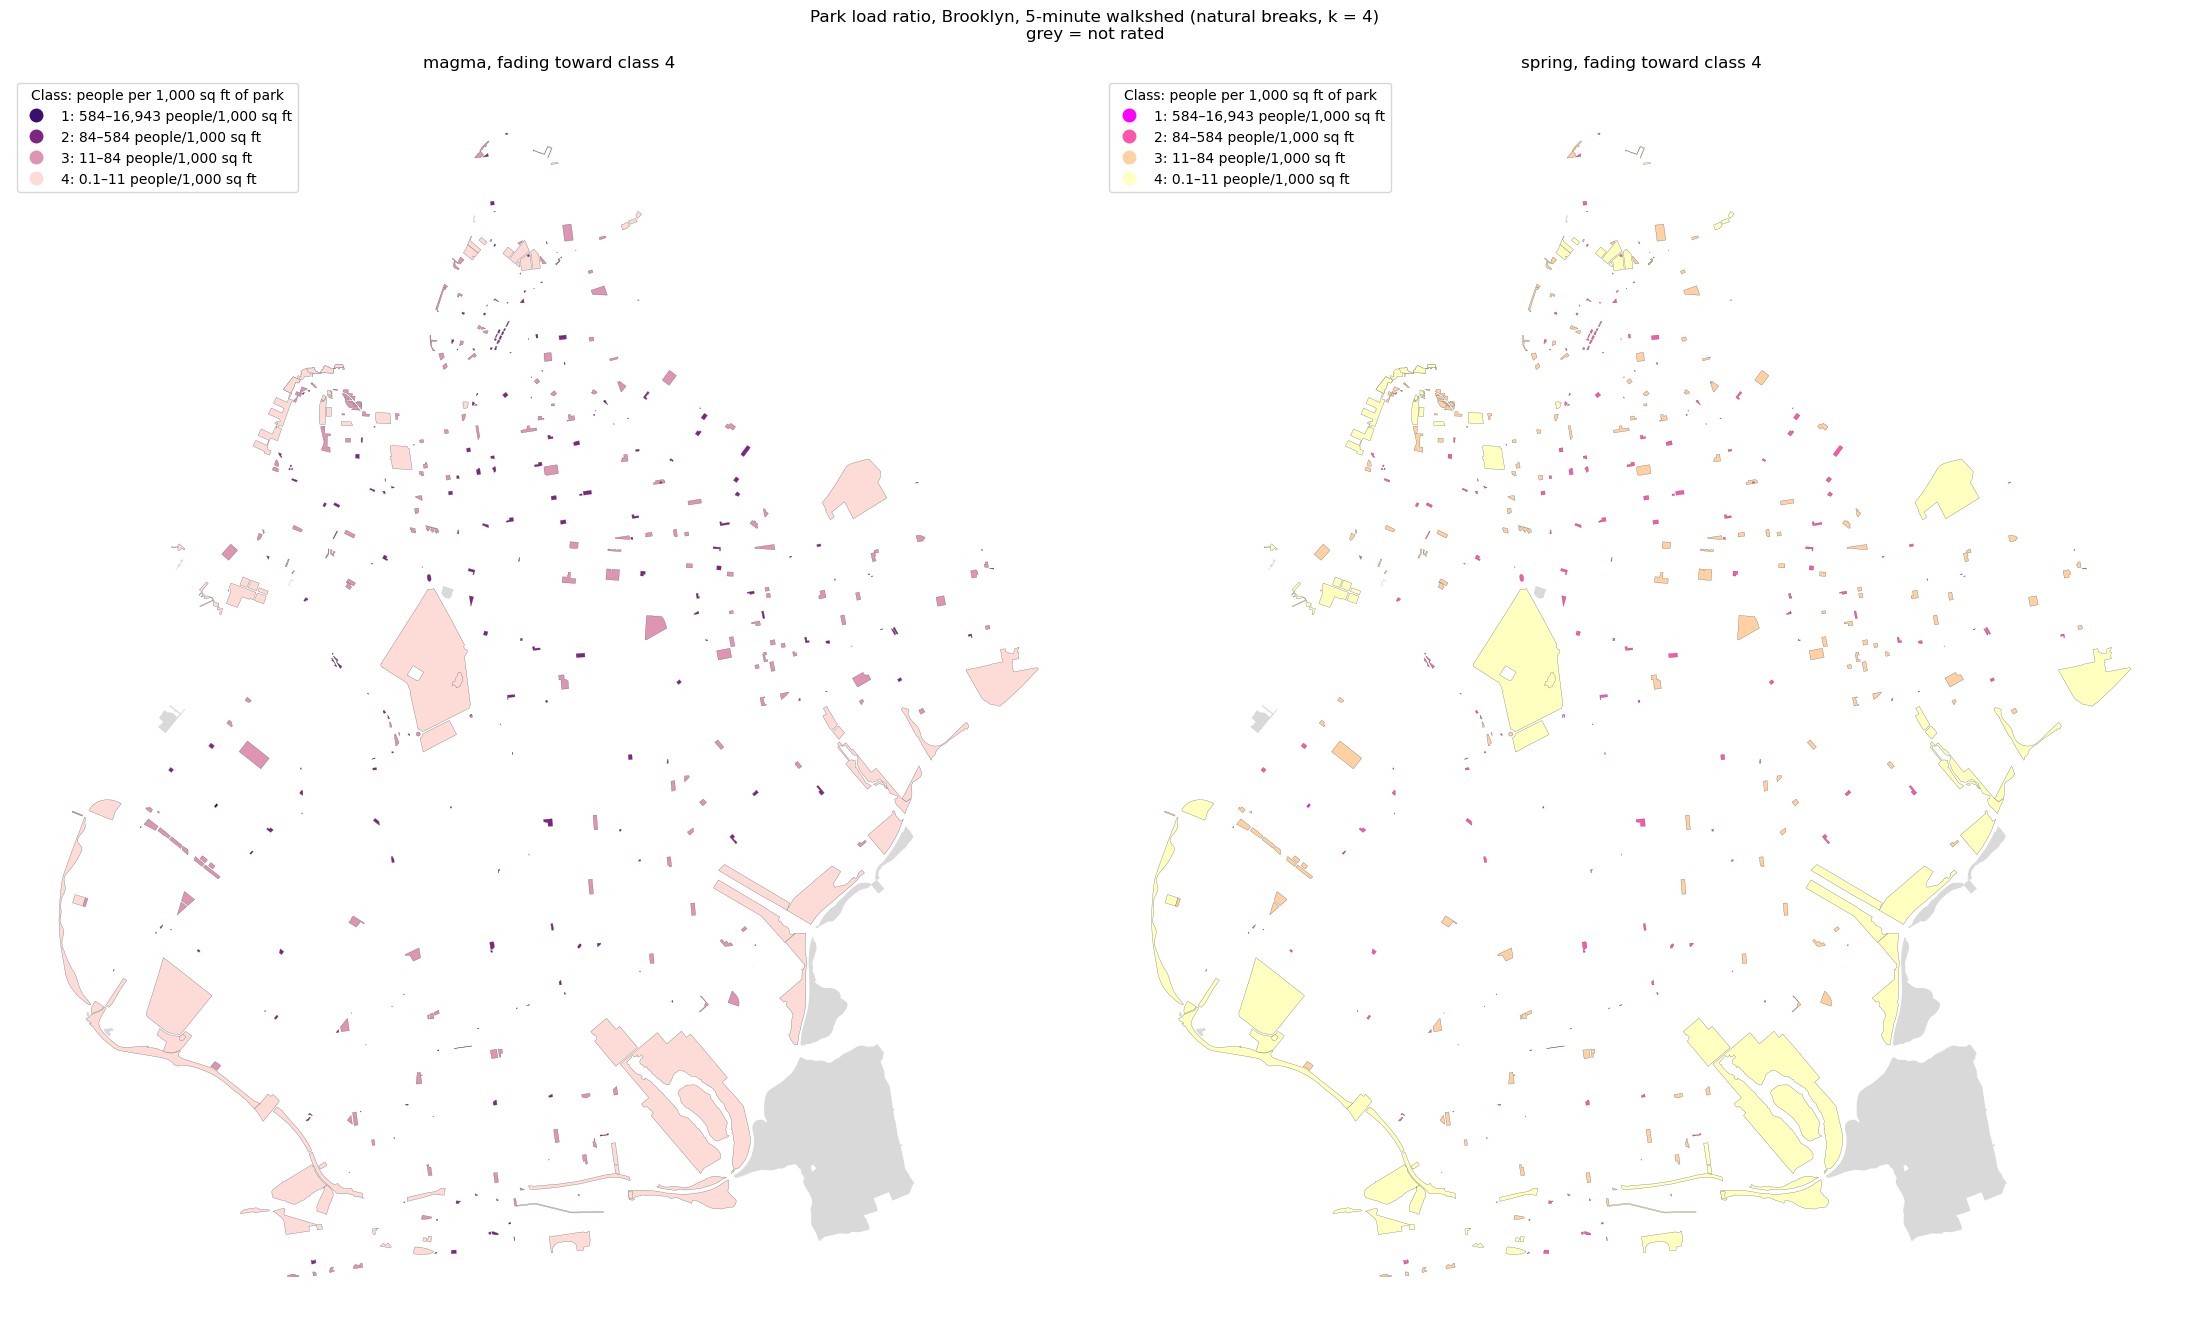

In [251]:
fig, axes = plt.subplots(1, 2, figsize=(22, 14))
for ax, (cmap, cmap_range, vibrancy) in zip(axes, COLORMAPS):
    parks[parks["load"] == 0].plot(ax=ax, color="#d9d9d9", edgecolor="none")
    bk_parks.plot(
        ax=ax,
        column="class_label",
        categorical=True,
        cmap=ListedColormap(class_colors(bk_k, cmap, cmap_range, vibrancy)),
        edgecolor="#555555",
        linewidth=0.2,
        legend=True,
        legend_kwds={
            "title": "Class: people per 1,000 sq ft of park",
            "loc": "upper left",
        },
    )
    ax.set_title(cmap if vibrancy is None else f"{cmap}, fading toward class {bk_k}")
    ax.set_axis_off()

fig.suptitle(
    f"Park load ratio, Brooklyn, {MINUTES}-minute walkshed (natural breaks, k = {bk_k})\n"
    "grey = not rated"
)
plt.tight_layout()
plt.show()

## 17. Export

Test-area results (`ParkLoad5_Bkyln_SampleNeighborhood_Test.csv` / `.html`), the Brooklyn table (`ParkLoad5_Bkyln.csv`), plus `bklyn_park_load_ratio.parquet` (every park, with class and colour columns) for `Park_Walksheds_Bklyn.ipynb`.

In [ ]:
if not USE_TOY_DATA:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    # Test area
    gpkg = OUT_DIR / "park_load_ratio_test.gpkg"
    test_parks.drop(columns=["has_walkshed", "no_residents"]).to_file(
        gpkg, layer="test_parks", driver="GPKG"
    )
    no_access[no_access[LOT_NTA].isin(STUDY_NTAS)].to_file(
        gpkg, layer="no_access_lots_study", driver="GPKG"
    )
    results.to_csv(OUT_DIR / f"{EXPORT_NAME_TEST}.csv", index=False)
    m.save(OUT_DIR / f"{EXPORT_NAME_TEST}.html")

    # Brooklyn: every park, with class columns empty for parks that aren't rated
    class_cols = ["acres", "load_class", "class_range", "class_label", "class_color"]
    bk_out = parks.merge(bk_parks[[PARK_ID] + class_cols], on=PARK_ID, how="left")
    bk_out["acres"] = bk_out["area_sqft"] / 43_560
    bk_out["load_class"] = bk_out["load_class"].astype("Int64")
    bk_out[
        [
            PARK_ID,
            PARK_NAME,
            "area_sqft",
            "load",
            "people_per_1000sqft",
            "sqft_per_person",
            "has_walkshed",
            "geometry",
        ]
        + class_cols
    ].to_parquet(OUT_DIR / "bklyn_park_load_ratio.parquet")
    bk_results.to_csv(OUT_DIR / f"{EXPORT_NAME_BK}.csv", index=False)

    print("Saved to", OUT_DIR)

## 18. Walkshed pull-back for overloaded parks

**Question:** if an overloaded park could only serve as many people as its area supports, how far would its walkshed reach?

A park is **overloaded** when $C_j = 1000\,L_j / A_j$ > `TARGET_MAX` (81 people per 1,000 sq ft, the upper bound of Brooklyn class 3). Its **capacity** is the load it would carry at exactly the benchmark:

$$K_j = \text{TARGET\_MAX} \times A_j / 1000 \quad \text{(people)}$$

**Capacity fill by distance**, for each overloaded park:
1. Take the lots whose centroid is in the park's `BASE_MINUTES` walkshed (the same membership as sections 6–9).
2. Measure each lot centroid's straight-line distance to the park polygon (0 if inside).
3. Sort nearest first and add up each lot's share $P_i / N_i$. $N_i$ stays at its original 5-minute value, so each park is adjusted independently and no other walkshed changes.
4. Keep adding lots while the running total is ≤ $K_j$. The **reach** $d_j$ is the distance of the last lot kept. A lot at exactly the same distance as the first dropped lot is dropped too, because a reach that includes one includes both.
5. Adjusted walkshed = original walkshed ∩ `park.buffer(d_j)`.
6. If even the nearest lot exceeds $K_j$: $d_j = 0$, the adjusted walkshed is empty, and the status is `cannot_meet_benchmark`.

Parks at or under the benchmark keep their full walkshed (`unchanged`), and so do parks with no walkshed or no residents.

People dropped from a pulled-back walkshed are **not reassigned** to another park; `pop_dropped` reports them. The "after" numbers come from the kept lots. The adjusted polygon is for mapping.

The pull-back runs on **every Brooklyn park**. The figure in section 20 zooms to the test-area parks.

In [253]:
import shapely

assert (
    MINUTES == BASE_MINUTES
), "membership (sections 6–9) must be built from the BASE_MINUTES walksheds"

lot_xy = lot_pts.set_index(LOT_ID).geometry
park_geom = parks.set_index(PARK_ID).geometry
shed_geom = walksheds.dissolve(
    by=WALK_PARK_ID
).geometry  # one BASE_MINUTES walkshed per park
members = dict(tuple(membership.groupby(PARK_ID)))


def pull_back(pid, capacity):
    """Nearest-first capacity fill for one park.
    Returns (kept lot ids, reach_ft, distance of the first dropped lot or inf)."""
    grp = members[pid]
    dist = lot_xy.loc[grp[LOT_ID]].distance(park_geom[pid]).to_numpy()
    order = np.argsort(dist, kind="stable")
    dist = dist[order]
    share = grp["pop_share"].to_numpy()[order]
    ids = grp[LOT_ID].to_numpy()[order]

    n_keep = int((np.cumsum(share) <= capacity + 1e-9).sum())
    if n_keep < len(dist):
        # Drop lots tied in distance with the first dropped lot
        n_keep = int((dist[:n_keep] < dist[n_keep]).sum())
    next_dist = float(dist[n_keep]) if n_keep < len(dist) else np.inf
    if n_keep == 0:
        return ids[:0], 0.0, next_dist
    return ids[:n_keep], float(dist[n_keep - 1]), next_dist


def polygonal(geom):
    """Keep only the polygon parts of an intersection result."""
    if geom.geom_type == "GeometryCollection":
        return shapely.union_all(
            [g for g in geom.geoms if g.geom_type in ("Polygon", "MultiPolygon")]
        )
    return geom


# Re-runnable: clear columns from a previous run of this cell
pullback_cols = [
    "capacity",
    "people_per_1000sqft_before",
    "people_per_1000sqft_after",
    "reach_ft",
    "pop_served_before",
    "pop_served_after",
    "pop_dropped",
    "pullback_status",
]
parks = parks.drop(columns=[c for c in pullback_cols if c in parks.columns])
parks["capacity"] = TARGET_MAX * parks["area_sqft"] / 1000

pk = parks.set_index(PARK_ID)
kept_lots, records = {}, []
for pid in pk.index[pk["has_walkshed"]]:
    load, capacity = pk.at[pid, "load"], pk.at[pid, "capacity"]
    if pk.at[pid, "people_per_1000sqft"] <= TARGET_MAX:
        records.append((pid, "unchanged", np.nan, load, shed_geom[pid]))
        continue
    kept, reach, next_dist = pull_back(pid, capacity)
    kept_lots[pid] = list(kept)
    if len(kept) == 0:
        records.append((pid, "cannot_meet_benchmark", 0.0, 0.0, None))
    else:
        served = members[pid].set_index(LOT_ID).loc[kept, "pop_share"].sum()
        # Pad the reach slightly so the last kept lot isn't lost to buffer rounding,
        # but by less than half the gap to the first dropped lot (row-house lots can be < 0.1 ft apart)
        pad = min(0.5, (next_dist - reach) / 2)
        geom = polygonal(
            shed_geom[pid].intersection(
                park_geom[pid].buffer(reach + pad, quad_segs=64)
            )
        )
        records.append((pid, "pulled_back", reach, served, geom))

adjusted_walksheds = gpd.GeoDataFrame(
    records,
    columns=[PARK_ID, "pullback_status", "reach_ft", "pop_served_after", "geometry"],
    geometry="geometry",
    crs=CRS,
)

parks = parks.merge(adjusted_walksheds.drop(columns="geometry"), on=PARK_ID, how="left")
parks["pullback_status"] = parks["pullback_status"].fillna(
    "unchanged"
)  # parks with no walkshed
parks["pop_served_before"] = parks["load"]
parks["pop_served_after"] = parks["pop_served_after"].fillna(parks["load"])
parks["pop_dropped"] = parks["pop_served_before"] - parks["pop_served_after"]
parks["people_per_1000sqft_before"] = parks["people_per_1000sqft"]
parks["people_per_1000sqft_after"] = (
    1000 * parks["pop_served_after"] / parks["area_sqft"]
)

adjusted_walksheds = adjusted_walksheds.drop(columns="pop_served_after").merge(
    parks[
        [
            PARK_ID,
            PARK_NAME,
            "people_per_1000sqft_before",
            "people_per_1000sqft_after",
            "pop_served_before",
            "pop_served_after",
            "pop_dropped",
        ]
    ],
    on=PARK_ID,
)

print(parks["pullback_status"].value_counts().to_string())
parks.loc[
    parks["pullback_status"] != "unchanged",
    [
        PARK_ID,
        PARK_NAME,
        "people_per_1000sqft_before",
        "people_per_1000sqft_after",
        "reach_ft",
        "pop_served_before",
        "pop_served_after",
        "pop_dropped",
        "pullback_status",
    ],
].sort_values("people_per_1000sqft_before", ascending=False).round(1).head(15)

pullback_status
unchanged                242
pulled_back              228
cannot_meet_benchmark      2


,park_id,park_name,people_per_1000sqft_before,people_per_1000sqft_after,reach_ft,pop_served_before,pop_served_after,pop_dropped,pullback_status
326,326,Ketchum Triangle,16942.9,75.6,156.1,8838.2,39.4,8798.8,pulled_back
315,315,Samuel Goldberg Triangle,12835.8,46.8,174.5,10119.5,36.9,10082.6,pulled_back
313,313,NaN,12450.1,0.0,0.0,6247.8,0.0,6247.8,cannot_meet_benchmark
280,280,Alben Square,9455.6,78.4,166.5,13084.0,108.5,12975.5,pulled_back
417,417,NaN,8228.8,79.4,192.3,1135.4,11.0,1124.5,pulled_back
278,278,NaN,7978.6,80.4,126.6,5230.0,52.7,5177.3,pulled_back
261,261,Gravesend Triangle,7952.5,79.6,140.0,6303.1,63.1,6239.9,pulled_back
288,288,Green street,7360.7,3.5,92.1,6041.5,2.9,6038.6,pulled_back
413,413,Greenstreets,7163.2,60.2,145.8,10111.3,85.0,10026.3,pulled_back
418,418,NaN,6781.1,76.2,198.9,1084.5,12.2,1072.3,pulled_back


## 19. Pull-back checks

**Toy park 3, by hand.** Park 3 is 20 × 50 ft = 1,000 sq ft. Its walkshed holds three lots that no other park reaches ($N_i = 1$):

| Lot | People | Distance to park |
|---|---|---|
| D | 40 | 30 ft |
| E | 30 | 80 ft |
| F | 50 | 180 ft |

- Before: $L_3 = 40 + 30 + 50 = 120$, so $C_3 = 1000 \times 120 / 1000 = 120$ > 81: overloaded.
- Capacity: $K_3 = 81 \times 1000 / 1000 = 81$ people.
- Fill nearest first: D → 40 (≤ 81, keep), E → 70 (≤ 81, keep), F → 120 (> 81, stop).
- Keeps **D and E**. Reach $d_3$ = **80 ft** (lot E). After: $C_3 = 1000 \times 70 / 1000 =$ **70** people per 1,000 sq ft, with **50** people dropped.
- Parks 1 and 2 (6.67 and 26.67) are under 81 and stay `unchanged`.

**Every run:** pulled-back parks end at or under `TARGET_MAX`; before = after + dropped for every park; unchanged parks drop nobody. A geometry check confirms each adjusted walkshed holds exactly the lot centroids that were kept.

In [254]:
pulled = parks["pullback_status"] == "pulled_back"
assert (
    parks.loc[pulled, "people_per_1000sqft_after"] <= TARGET_MAX + 1e-9
).all(), "a pulled-back park is still over TARGET_MAX"
assert np.allclose(
    parks["pop_served_after"] + parks["pop_dropped"], parks["pop_served_before"]
)
assert (
    parks.loc[parks["pullback_status"] == "unchanged", "pop_dropped"].abs() < 1e-9
).all()
assert (
    parks.loc[parks["pullback_status"] == "cannot_meet_benchmark", "pop_served_after"]
    == 0
).all()

# Geometry check: lot centroids inside each adjusted walkshed = lots kept.
# Buffers are polygons approximating a curve, so lots within 1 ft of the reach can land
# on the wrong side; those are counted, not failed. The numbers above use the kept lots.
adj = adjusted_walksheds.set_index(PARK_ID).geometry
reach_by_id = parks.set_index(PARK_ID)["reach_ft"]
hard, near_edge = [], 0
for pid in parks.loc[pulled, PARK_ID]:
    ids = members[pid][LOT_ID].to_numpy()
    inside = set(ids[lot_xy.loc[ids].within(adj[pid]).to_numpy()])
    for lid in inside ^ set(kept_lots[pid]):
        if abs(lot_xy[lid].distance(park_geom[pid]) - reach_by_id[pid]) < 1:
            near_edge += 1
        else:
            hard.append((pid, lid))
assert not hard, f"adjusted walksheds don't match kept lots: {hard[:10]}"
print(
    f"Checks passed for {pulled.sum()} pulled-back parks "
    f"({near_edge} lots within 1 ft of a reach edge drawn on the other side)"
)

if USE_TOY_DATA:
    p3 = parks.set_index(PARK_ID).loc[3]
    assert np.isclose(p3["capacity"], 81)
    assert kept_lots[3] == ["D", "E"], kept_lots[3]
    assert np.isclose(p3["reach_ft"], 80)
    assert np.isclose(p3["people_per_1000sqft_after"], 70)
    assert np.isclose(p3["pop_dropped"], 50)
    assert p3["pullback_status"] == "pulled_back"
    assert (
        parks.set_index(PARK_ID).loc[[1, 2], "pullback_status"] == "unchanged"
    ).all()
    print(
        "Toy park 3 matches hand calculation: K = 81, keeps D and E, reach = 80 ft, after = 70 ✓"
    )

Checks passed for 228 pulled-back parks (8 lots within 1 ft of a reach edge drawn on the other side)


## 20. Figure: walksheds before and after pull-back

Same style as the Brooklyn-wide static map in `Park_Walksheds_Bklyn.ipynb` §14, zoomed to the test-area parks.

- **Left, before:** the full 5-minute walksheds of the test-area parks (`WALKSHED_BLUE`, `#2c7fb8`).
- **Right, after:** the area still covered after the pull-back (same blue) and the coverage lost, drawn as walkshed-blue halftone dots on a light blue (`BLUE_VIBRANCY`): a checkerboard of large and small dots on a fixed map grid (`DOT_SPACING_FT`, `DOT_BIG`, `DOT_SMALL`).
- **Parks** are coloured by load class with a white outline: the class *before* pull-back on the left and *after* on the right. Both sides use the **Brooklyn class breaks from section 16**. Parks that aren't rated (no walkshed, or no residents in it) serve nobody and are drawn in the class 4 colour. Parks that can't meet the benchmark are white with a teal outline on the right.
- A faint, unlabelled street map from the LION network sits underneath; walkshed fills are slightly see-through (`WALKSHED_ALPHA`) so it shows through; parks have a white outline so they read against the blue. The black line is the study area.

**Display shape.** With `SHED_STYLE = "solid"`, each walkshed is drawn as one continuous area instead of a set of buffered streets. Gaps between reachable streets are closed across the parcels between them (grow by `SOLID_CLOSE_FT`, then shrink back by the same amount), and interior holes are filled. Pulled-back walksheds are the solid shape cut to the park's reach. This only changes the drawing: it adds roughly 10–35% area at the edges, but every number above comes from the street-based walksheds.

**Pedestrian plazas and open streets** (NYC DOT, Brooklyn) are drawn on both panels in `INFRA_COLOR` (`#c98f22`), plazas with a white outline like the parks and open streets as lines with a thin white edge.

In [255]:
from shapely.geometry import Polygon


def solidify(geom, close_ft=SOLID_CLOSE_FT, max_hole_sqft=5_000_000):
    """Display shape: close gaps between reachable streets (grow, then shrink, by close_ft) and fill holes."""
    if geom is None or geom.is_empty:
        return geom
    closed = geom.buffer(close_ft, quad_segs=8).buffer(-close_ft, quad_segs=8)
    polys = getattr(closed, "geoms", [closed])
    return shapely.union_all(
        [
            Polygon(
                p.exterior, [r for r in p.interiors if Polygon(r).area > max_hole_sqft]
            )
            for p in polys
        ]
    )


def display_sheds(pids):
    """Before and after walkshed shapes to draw for the given parks, following SHED_STYLE."""
    status = parks.set_index(PARK_ID)["pullback_status"]
    reach = parks.set_index(PARK_ID)["reach_ft"]
    adj = adjusted_walksheds.set_index(PARK_ID).geometry
    before, after = {}, {}
    for pid in pids:
        if pid not in shed_geom.index:
            continue  # no walkshed
        before[pid] = (
            solidify(shed_geom[pid]) if SHED_STYLE == "solid" else shed_geom[pid]
        )
        if status[pid] == "cannot_meet_benchmark":
            continue
        if status[pid] == "pulled_back" and SHED_STYLE == "solid":
            after[pid] = before[pid].intersection(
                park_geom[pid].buffer(reach[pid] + 0.5, quad_segs=64)
            )
        elif status[pid] == "pulled_back":
            after[pid] = adj[pid]
        else:
            after[pid] = before[pid]
    to_gdf = lambda d: gpd.GeoDataFrame(
        {PARK_ID: list(d)}, geometry=list(d.values()), crs=CRS
    )
    return to_gdf(before), to_gdf(after)

In [ ]:
import logging

from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from matplotlib.patches import Patch

WALKSHED_BLUE = "#2c7fb8"
BLUE_VIBRANCY = 0.2  # light blue behind the coverage-lost dots: share of full colour (1 = full, 0 = white)
DOT_COLOR = WALKSHED_BLUE  # coverage lost: halftone dots in the walkshed blue, on the light blue
INFRA_COLOR = "#c98f22"  # pedestrian plazas and open streets
OPEN_STREET_WIDTH = 1.5  # open-street line width (pt); a white edge is drawn underneath
DOT_SPACING_FT = 150  # distance between neighbouring dots on the map
DOT_BIG, DOT_SMALL = 0.5, 0.27  # dot diameter as a share of the spacing (r 1.5 and 0.8 in a 12 px tile)
WALKSHED_ALPHA = 0.7  # walkshed fills are slightly see-through so the street map shows underneath
STREET_COLOR = "#cfcfcf"  # faint street map drawn from the LION network (no labels)
STREET_WIDTH = 0.3
LION_PATH = ROOT / "lion_ped.parquet"
PED_PLAZAS_PATH = ROOT / "Data_Input/Lingering Infrastructure/NYC_DOT_Pedestrian_Plazas_-_Polygon_20261019.geojson"
OPEN_STREETS_PATH = ROOT / "Data_Input/Lingering Infrastructure/Open_Streets_Locations_20261019.geojson"
CANNOT_COLOR = "#00a6a6"


def save_clean(fig, path, dpi=300):
    """Save the map panels only: no title, panel titles or legend."""
    texts = [fig._suptitle, *fig.legends, *(ax.title for ax in fig.axes)]
    hidden = [t for t in texts if t is not None and t.get_visible()]
    for t in hidden:
        t.set_visible(False)
    fig.savefig(path, dpi=dpi, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    for t in hidden:
        t.set_visible(True)


def mute(color, vibrancy=BLUE_VIBRANCY):
    """Blend a colour toward white."""
    return to_hex([v * vibrancy + (1 - vibrancy) for v in to_rgb(color)])


def draw_halftone(ax, geom, pts_per_ft):
    """Checkerboard of large and small dots on a fixed map grid, clipped to geom (no fill behind)."""
    s = DOT_SPACING_FT
    minx, miny, maxx, maxy = geom.bounds
    i = np.arange(np.floor(minx / s), np.ceil(maxx / s) + 1)
    j = np.arange(np.floor(miny / s), np.ceil(maxy / s) + 1)
    gi, gj = np.meshgrid(i, j)
    x, y = (gi * s).ravel(), (gj * s).ravel()
    shapely.prepare(geom)
    inside = shapely.contains_xy(geom, x, y)
    big = ((gi + gj) % 2 == 0).ravel()
    for mask, frac in ((big, DOT_BIG), (~big, DOT_SMALL)):
        size_pt = frac * s * pts_per_ft  # marker diameter in points
        ax.scatter(x[inside & mask], y[inside & mask], s=size_pt**2, color=DOT_COLOR, alpha=WALKSHED_ALPHA, linewidths=0)


# Fixed Brooklyn breaks (section 16): each class's upper bound, lowest class first
class_upper = (
    bk_parks.groupby("load_class")["people_per_1000sqft"]
    .max()
    .sort_index(ascending=False)
)
class_range = bk_parks.groupby("load_class")["class_range"].first()
colors = dict(enumerate(class_colors(bk_k), start=1))


def fixed_class(values):
    """Class under the fixed Brooklyn breaks (1 = most crowded); 0 where nobody is served."""
    b = np.minimum(
        np.searchsorted(class_upper.to_numpy(), values, side="left"), bk_k - 1
    )
    return np.where(np.asarray(values) > 0, bk_k - b, 0)


# Walkshed areas for the test-area parks (shapes follow SHED_STYLE)
fig_ids = test_parks[PARK_ID]
sheds_before, sheds_after = display_sheds(fig_ids)
show_before = sheds_before.union_all()
show_after = sheds_after.union_all()
show_lost = show_before.difference(show_after)
xmin, ymin, xmax, ymax = sheds_before.total_bounds

# Every park in view, coloured by class before / after
park_map = parks[[PARK_ID, PARK_NAME, "pullback_status", "load", "geometry"]].copy()
park_map["class_before"] = fixed_class(parks["people_per_1000sqft_before"])
park_map["class_after"] = fixed_class(parks["people_per_1000sqft_after"])
not_rated = park_map["load"] == 0  # no walkshed, or no residents in it: serves nobody
park_map.loc[not_rated, ["class_before", "class_after"]] = bk_k
cannot = park_map[park_map["pullback_status"] == "cannot_meet_benchmark"]
cannot_in_view = cannot.cx[xmin:xmax, ymin:ymax]

streets_in_view = None
if not USE_TOY_DATA:
    streets_in_view = gpd.read_parquet(LION_PATH, columns=["geometry"]).to_crs(CRS).cx[xmin:xmax, ymin:ymax]

# Pedestrian plazas and open streets (Brooklyn)
plazas = open_streets = None
if not USE_TOY_DATA:
    logging.getLogger("pyogrio").setLevel(logging.ERROR)  # the open-streets file has field types GDAL skips noisily
    plazas = gpd.read_file(PED_PLAZAS_PATH).to_crs(CRS)
    plazas = plazas[plazas["boroname"] == "Brooklyn"]
    open_streets = gpd.read_file(OPEN_STREETS_PATH).to_crs(CRS)
    open_streets = open_streets[open_streets["boroughname"] == "Brooklyn"]


def draw_infra(ax):
    """Pedestrian plazas and open streets in INFRA_COLOR, with a white edge like the parks."""
    if plazas is None:
        return
    plazas.plot(ax=ax, color=INFRA_COLOR, edgecolor="white", linewidth=0.5)
    open_streets.plot(
        ax=ax, color=INFRA_COLOR, linewidth=OPEN_STREET_WIDTH,
        path_effects=[pe.Stroke(linewidth=OPEN_STREET_WIDTH + 1.2, foreground="white"), pe.Normal()],
    )


def draw_parks(ax, class_col):
    for c in sorted(colors, reverse=True):  # least crowded first, most crowded on top
        sel = park_map[park_map[class_col] == c]
        if len(sel):
            sel.plot(ax=ax, color=colors[c], edgecolor="white", linewidth=0.5)


fig, axes = plt.subplots(1, 2, figsize=(22, 12))
pts_per_ft = 11 * 0.95 * 72 / (xmax - xmin)  # map scale in points per foot, for halftone dot sizes
for ax, side in zip(axes, ("before", "after")):
    if streets_in_view is not None:
        streets_in_view.plot(ax=ax, color=STREET_COLOR, linewidth=STREET_WIDTH, zorder=0)
    if side == "before":
        gpd.GeoSeries([show_before], crs=CRS).plot(
            ax=ax, color=WALKSHED_BLUE, edgecolor="none", alpha=WALKSHED_ALPHA
        )
        draw_parks(ax, "class_before")
        ax.set_title("Before: full 5-minute walksheds", fontsize=13)
    else:
        gpd.GeoSeries([show_lost], crs=CRS).plot(
            ax=ax, color=mute(WALKSHED_BLUE), edgecolor="none", alpha=WALKSHED_ALPHA
        )
        draw_halftone(ax, show_lost, pts_per_ft)
        gpd.GeoSeries([show_after], crs=CRS).plot(
            ax=ax, color=WALKSHED_BLUE, edgecolor="none", alpha=WALKSHED_ALPHA
        )
        draw_parks(ax, "class_after")
        if len(cannot):
            cannot.plot(ax=ax, color="white", edgecolor=CANNOT_COLOR, linewidth=2)
        ax.set_title("After: walksheds pulled back to the benchmark", fontsize=13)
    draw_infra(ax)
    study_area.boundary.plot(ax=ax, color="black", linewidth=1)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_axis_off()

handles = [
    Patch(facecolor=WALKSHED_BLUE, alpha=WALKSHED_ALPHA, label="5-minute walkshed"),
    Patch(facecolor=mute(WALKSHED_BLUE), edgecolor=DOT_COLOR, hatch="..", linewidth=0, label="Coverage lost after pull-back"),
    Line2D([], [], color="black", linewidth=1, label="Study area"),
]
if plazas is not None:
    handles += [
        Patch(facecolor=INFRA_COLOR, edgecolor="white", label="Pedestrian plaza"),
        Line2D([], [], color=INFRA_COLOR, linewidth=OPEN_STREET_WIDTH, label="Open street"),
    ]
handles += [
    Patch(
        facecolor=colors[c],
        edgecolor="#555555",
        label=f"Class {c}: {class_range[c]}" + (" (incl. parks not rated)" if c == bk_k else ""),
    )
    for c in sorted(colors)
]
if len(cannot_in_view):
    names = cannot_in_view[PARK_NAME].fillna("unnamed").tolist()
    listed = ", ".join(names[:8]) + (f" (+{len(names) - 8} more)" if len(names) > 8 else "")
    handles.append(
        Patch(facecolor="white", edgecolor=CANNOT_COLOR, linewidth=2, label=f"Cannot meet benchmark: {listed}")
    )
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=10,
           title="Park load class: people per 1,000 sq ft of park")
fig.suptitle(
    f"{BASE_MINUTES}-minute walksheds before and after pull-back to ≤ {TARGET_MAX:g} people per 1,000 sq ft",
    fontsize=14,
)
plt.tight_layout(rect=(0, 0.08, 1, 0.97))
if not USE_TOY_DATA:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUT_DIR / f"{EXPORT_NAME_TEST}_Labeled.png", dpi=200, bbox_inches="tight")
    save_clean(fig, OUT_DIR / f"{EXPORT_NAME_TEST}.png")  # maps only, no text
plt.show()

for label, sel in [
    ("Brooklyn", parks),
    ("Test-area parks (figure)", parks[parks[PARK_ID].isin(fig_ids)]),
]:
    is_pulled = sel["pullback_status"] == "pulled_back"
    is_cannot = sel["pullback_status"] == "cannot_meet_benchmark"
    print(
        f"{label}: {is_pulled.sum()} parks pulled back, {is_cannot.sum()} cannot meet the benchmark, "
        f"{sel.loc[is_pulled, 'pop_dropped'].sum():,.0f} people dropped from pulled-back walksheds "
        f"(+{sel.loc[is_cannot, 'pop_dropped'].sum():,.0f} from parks that cannot meet it)"
    )

## 21. Export: adjusted walksheds

Adds an `adjusted_walksheds` layer to `park_load_ratio_test.gpkg`: one row per park with a walkshed, with its status, reach and before/after numbers. The geometry is empty for `cannot_meet_benchmark` parks.

In [257]:
if not USE_TOY_DATA:
    gpkg = OUT_DIR / "park_load_ratio_test.gpkg"
    adjusted_walksheds.to_file(gpkg, layer="adjusted_walksheds", driver="GPKG")
    print(
        f"Wrote {len(adjusted_walksheds)} adjusted walksheds to {gpkg.name}, layer 'adjusted_walksheds'"
    )

Wrote 465 adjusted walksheds to park_load_ratio_test.gpkg, layer 'adjusted_walksheds'
